# Confronto tra Insertion Sort e Heap Sort

## Insertion Sort
### Breve descrizione dell'algoritmo
Insertion Sort è un algoritmo che esegue l'ordinamento dell'array sul posto. È un buon algoritmo per pochi elementi. Funziona prendendo un elemento dell'array alla volta, partendo dal secondo. Si confronta l'elemento con quelli nel sottoarray a sinistra dell'elemento selezionato (già ordinato) e lo si inserisce nella posizione corretta, in modo che questo sottoarray rimanga ordinato. È fondamentale, per il funzionamento corretto dell'algoritmo, che il sottoarray sinistro sia ordinato a ogni iterazione.
### Spiegazione del codice
- L'algoritmo prende come input l'array da ordinare
- Si itera tramite `i` partendo dal secondo elemento dell'array
- Si salva, nella variabile `key`, il valore attuale da inserire nella posizione giusta
- Si scorre, tramite `j` che parte da `i-1`, il sottoarray sinistro, finché non troveremo un valore minore di `key` oppure finché non si arriva in testa alla coda
- L'elemento con cui viene confrontato `key` viene spostato in avanti di una posizione e `j` viene decrementato di 1
- Infine viene inserito l'elemento `key` nella posizione corretta `j+1`
- Con questi passaggi si mantiene l'ordine del sottoarray a sinistra dell'elemento corrente e, di conseguenza, l'ordinamento di tutto l'array dopo l'ultima iterazione

In [1]:
def insertion_sort(array):
    for i in range(1, len(array)):
        key = array[i]
        j = i - 1
        while j >= 0 and array[j] > key:
            array[j + 1] = array [j]
            j = j - 1
        array[j + 1] = key

### Complessità dell'algoritmo
Con n elementi nell'array da ordinare, abbiamo:
- **Caso migliore**: array già ordinato. Abbiamo $O(n)$ perché il ciclo interno non viene mai eseguito
- **Caso medio**: array con ordine casuale. Abbiamo $O(n^2)$
- **Caso peggiore**: array con ordine decrescente. Abbiamo $\Theta(n^2)$

## Heap Sort
Questo algoritmo utilizza una particolare struttura dati per gestire le informazioni, chiamata *heap*. Per questo è necessario descrivere prima quest'ultima.
### Struttura dati Heap
È un array che rappresenta un albero binario quasi completo, cioè un albero in cui tutti i livelli sono completamente riempiti, a eccezione dell'ultimo, che può essere riempito da sinistra fino a un certo punto. La **radice dell'albero** è all'indice 0 dell'array. Per **Heap Sort** sarà necessario ridurre la dimensione dell'heap, quindi creiamo una classa che rappresenti l'heap, con due attributi:
- `array`: contiene tutti gli elementi dell'heap
- `heap_size`: rappresenta la dimensione attuale dell'array

In [2]:
class Heap:
    def __init__(self, array):
        self.array = array
        self.heap_size = len(array)

Le seguenti procedure utilizzano l'indice **i** dell'elemento di partenza per calcolare gli indici del padre, del figlio destro e del figlio sinistro. Da notare che usano praticamente solo la moltiplicazione e la divisione per 2, che in un calcolatore vengono eseguite tramite un semplice shift, rispettivamente, a sinistra e a destra.

In [3]:
def parent(i):
    return i//2

def left(i):
    return 2*i

def right(i):
    return 2*i + 1

In questa implementazione verrà usato il **max-heap**, la cui proprietà di heap richiede che, per ogni nodo diverso dalla radice, il padre abbia valore maggiore dei figli, cioè `array[parent(i)] >= array[i]`. È necessaria quindi una procedura che conservi questa proprietà. Questa procedura, chiamata *max_heapify* deve essere chiamata ricorsivamente, perché assume che i sottoalberi con radici in `left(i)` e `right(i)` siano dei max-heap, ma che il valore `array[i]` possa essere più piccolo dei figli. Questa procedura ha un tempo di esecuzione di $O(\lg(n))$.
### Spiegazione del codice
- Viene determinato il valore più grande (**largest**) tra `array[i]`, `array[left(i)]` e `array[right(i)]`
- Adesso si hanno due possibilità:
    - `array[i]` è il più grande: non c'è niente da fare, il sottoalbero con radice in `array[i]` è già un max-heap
    - `array[i]` **non** è il più grande: scambia il più grande con `array[i]`. Adesso, in questo caso, il sottoalbero con radice in **largest** ha come valore di quest'ultima un numero più piccolo, quindi potrebbe violare la proprietà di heap. Per questo viene chiamata ricorsivamente su questo sottoalbero.

In [4]:
def max_heapify(heap: Heap, i):
    l = left(i)
    r = right(i)
    if l < heap.heap_size and heap.array[l] > heap.array[i]:
        largest = l
    else:
        largest = i
    if r < heap.heap_size and heap.array[r] > heap.array[i]:
        largest = r
    if largest != i:
        heap.array[i], heap.array[largest] = heap.array[largest], heap.array[i]
        max_heapify(heap, largest)

Serve un'altra funzione di supporto, cioè quella che costruisce un heap partendo da un generico array. Essendo un albero binario quasi completo, tutti gli elementi successivi all'indice `len(array)//2` sono foglie dell'albero. La funzione **build_max_heap** attraversa solo i nodi interni dell'albero, chiamando **max_heapify** in *bottom up*, cioè dal basso verso l'alto. Questa procedura ha un tempo di esecuzione di $O(n)$.

In [5]:
def build_max_heap(array):
    heap = Heap(array)
    for i in reversed(range(heap.heap_size//2)):
        max_heapify(heap, i)
    return heap

### Breve descrizione di Heap Sort
Anche Heap Sort è un algoritmo che ordina sul posto ma, a differenza dell'Insertion Sort, ha un tempo di esecuzione migliore. Sfrutta il fatto che, in un max-heap, la radice ha sempre il valore piu grande. Opera scambiando la radice, in posizione `array[1]`, con l'ultimo elemento dell'array, in posizione `array[heap_size]`. Poi esclude l'ultimo elemento dell'array perché adesso è nella posizione giusta. Infine chiama la procedura **max_heapify** per conservare la proprietà di max-heap. Ripete questo procedimento finché non raggiunge un max-heap di dimensione 2. Non ha senso arrivare alla dimensione 1 perché non ci sarebbero elementi con cui scambiare la radice.
### Spiegazione del codice
- Costruisce un max-heap
- Itera, tramite `i`, partendo dall'ultimo elemento dell'array
- Scambia la radice con l'ultimo elemento dell'heap
- Decrementa `heap_size`, in modo che l'operazione successiva non riporti il valore scambiato fino alla radice
- Esegue **max_heapify** per conservare la proprietà di max-heap, perché lo scambio ha messo alla radice un valore più piccolo dei figli
- Continua a iterare finché non arriva al secondo elemento dell'array, in posizione `i=1`


In [6]:
def heap_sort(array):
    heap = build_max_heap(array)
    for i in reversed(range(1, heap.heap_size)):
        heap.array[1], heap.array[i] = heap.array[i], heap.array[1]
        heap.heap_size -= 1
        max_heapify(heap, 1)

### Complessità dell'algoritmo
Con un array da ordinare di n elementi, abbiamo una chiamata a **build_max_heap** che ha costo $O(n)$, sommata a **n-1** chiamate di **max_heapify**, ciascuna con costo $O(lg(n))$. Non esistono input che generano il caso migliore e peggiore, quindi abbiamo che:
- **Caso migliore**: $O(n*lg(n))$
- **Caso medio**: $O(n*lg(n))$
- **Caso peggiore**: $O(n*lg(n))$


### Creazione degli array
Iniziamo definendo le funzioni per generare gli array da ordinare. Ne creiamo tre, una per generare un array ordinato, una per generare un array casuale e una per generare un array ordinato in modo inverso. Gli array sono implementati tramite delle semplici liste di Python. Tutte le funzioni prendo come input la dimensione. Generiamo questi tre tipi di array per vedere come cambiano i tempi di esecuzione per **Insertion Sort**.

In [7]:
def generate_sorted_array(size) -> list:
    array = []
    for i in range(size):
        array.append(i)
    return array

def generate_random_array(size) -> list:
    import numpy as np
    rng = np.random.default_rng()
    return [rng.integers(low=0, high=1000000).tolist() for _ in range(size)]

def generate_reversed_sorted_array(size) -> list:
    array = []
    for i in reversed(range(size)):
        array.append(i)
    return array

## Esecuzione dei test
Per eseguire i test utilizziamo il **perf_counter**, perché è ottimo per queste tipologie di test. Le funzioni **test_insertion_sort** e **test_heap_sort** misurano il tempo di esecuzione dei relativi algoritmi e lo restituiscono come valore di ritorno.

La funzione **run_tests** prende come parametri:
- `array_sizes`: lista che contiene le varie dimensioni degli array da ordinare+
- `array_order`: indica il tipo di array da generare (ordinato, ordinato inversamente, casuale), in base a quale test si vuole svolgere
- `graph_title`: titolo da inserire sul grafico che verrà generato, in base a quale test si vuole svolgere
- `file_id`: per creare il nome del file .png dove viene salvato il grafico generato

Questa funzione esegue l'ordinamento su uno stesso array un numero arbitrario di volte (indicato da `num_tests`) e calcola la **media dei tempi di esecuzione**. Infine crea un singolo grafico con le curve dei tempi di entrambi gli algoritmi, in modo che siano facilmente confrontabili.

In [8]:
from time import perf_counter

def test_insertion_sort(array):
    start = perf_counter()
    insertion_sort(array)
    end = perf_counter()
    return end - start

def test_heap_sort(array):
    start = perf_counter()
    heap_sort(array)
    end = perf_counter()
    return end - start

def run_tests(array_sizes: list, array_order: str, graph_title: str, file_id: int):
    num_tests = 7
    is_times = {}
    hs_times = {}
    for size in array_sizes:
        match array_order:
            case "sorted":
                array = generate_sorted_array(size)
            case "reverse_sorted":
                array = generate_reversed_sorted_array(size)
            case "random":
                array = generate_random_array(size)
            case _:
                raise Exception("array_order non esistente")
        is_time = 0
        hs_time = 0
        for _ in range(num_tests):
            is_time += test_insertion_sort(array.copy())
            hs_time += test_heap_sort(array.copy())
        is_times[size] = is_time / num_tests
        hs_times[size] = hs_time / num_tests

    import matplotlib.pyplot as plt

    plt.plot(array_sizes, is_times.values(), label="Insertion Sort")
    plt.plot(array_sizes, hs_times.values(), label="Heap Sort")
    plt.title(graph_title)
    plt.xlabel("Dimensione array")
    plt.ylabel("Tempo di esecuzione medio (sec)")
    plt.legend()

    plt.savefig("Grafico_" + str(file_id) + ".png")
    plt.show()

Visto che l'Insertion Sort è un buon algoritmo per array di pochi elementi, separiamo i test in 2 casi. Il primo con array di dimensioni molto grandi e il secondo con array di dimensioni più contenute.

## Test con array di grandi dimensioni
Definiamo le dimensioni degli array:

In [9]:
array_sizes = [i for i in range(2000, 12000 + 1, 2000)]
print(array_sizes)

[2000, 4000, 6000, 8000, 10000, 12000]


### Test con array ordinato
In questo test abbiamo il **caso migliore di Insertion Sort**, cioè $O(n)$, contro **Heap Sort**, che è sempre $O(n*lg(n))$. Ci aspettiamo quindi che Insertion Sort sia, in questo caso, **più rapido** di Heap Sort.

Grandi dimensioni: Esecuzione test con array ordinato


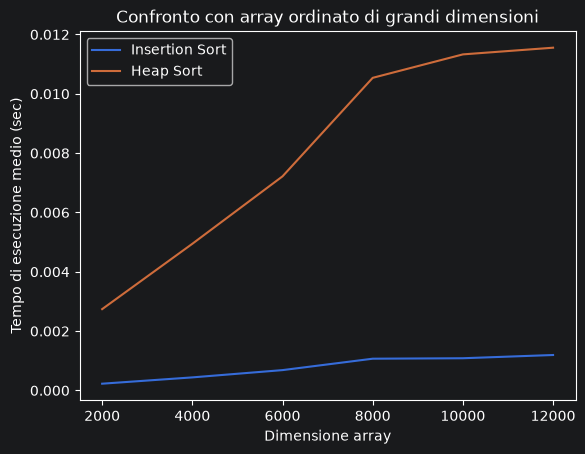

In [10]:
print("Grandi dimensioni: Esecuzione test con array ordinato")
run_tests(array_sizes, "sorted", "Confronto con array ordinato di grandi dimensioni", 1)

### Test con array casuale
In questo caso abbiamo il **caso medio di Insertion Sort**. Ci aspettiamo che Insertion Sort sia **più lento** di Heap Sort.

Grandi dimensioni: Esecuzione test con array casuale


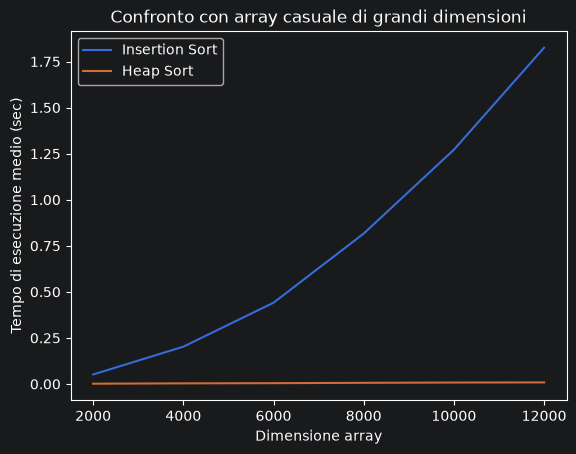

In [11]:
print("Grandi dimensioni: Esecuzione test con array casuale")
run_tests(array_sizes, "random", "Confronto con array casuale di grandi dimensioni", 2)

### Test con array ordinato al contrario
In questo test abbiamo il **caso peggiore di Insertion Sort**. Anche in questo caso ci aspettiamo che Insertion Sort sia **più lento** di Heap Sort.

Grandi dimensioni: Esecuzione test con array ordinato al contrario


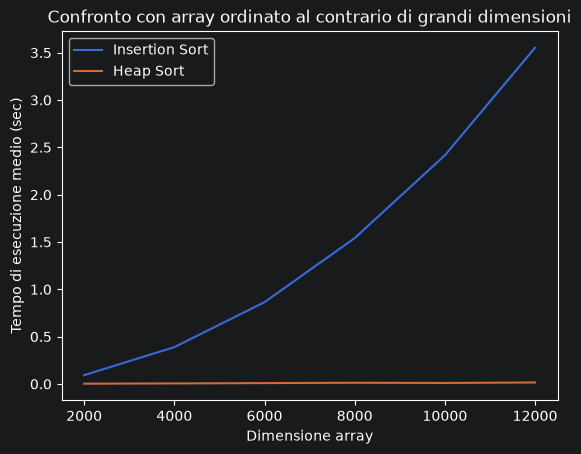

In [12]:
print("Grandi dimensioni: Esecuzione test con array ordinato al contrario")
run_tests(array_sizes, "reverse_sorted", "Confronto con array ordinato al contrario di grandi dimensioni", 3)

## Test con array di piccole dimensioni
Definiamo le dimensioni degli array:

In [13]:
array_sizes = [10, 20, 30, 50, 100]
print(array_sizes)

[10, 20, 30, 50, 100]


### Test con array ordinato

Piccole dimensioni: Esecuzione test con array ordinato


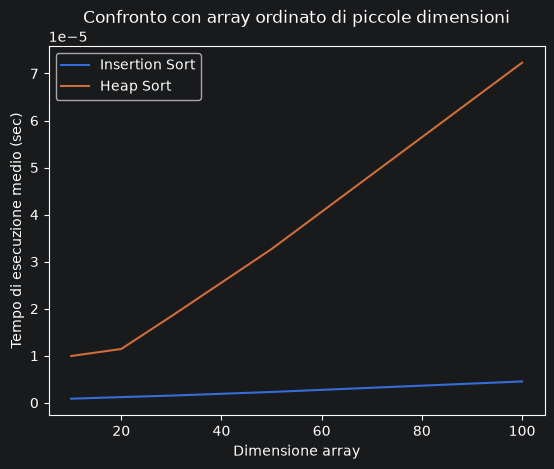

In [14]:
print("Piccole dimensioni: Esecuzione test con array ordinato")
run_tests(array_sizes, "sorted", "Confronto con array ordinato di piccole dimensioni", 4)

Era da aspettarsi un risultato del genere, visto che già con array di grandi dimensioni **Insertion Sort** è più veloce di **Heap Sort**

### Test con array casuale

Piccole dimensioni: Esecuzione test con array casuale


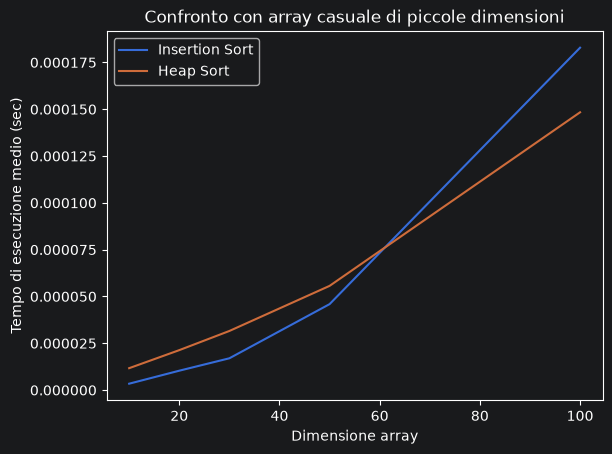

In [18]:
print("Piccole dimensioni: Esecuzione test con array casuale")
run_tests(array_sizes, "random", "Confronto con array casuale di piccole dimensioni", 5)

### Test con array ordinato al contrario

Piccole dimensioni: Esecuzione test con array ordinato al contrario


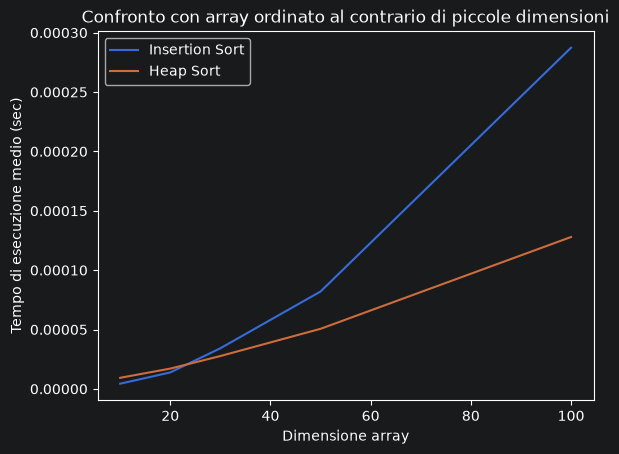

In [19]:
print("Piccole dimensioni: Esecuzione test con array ordinato al contrario")
run_tests(array_sizes, "reverse_sorted", "Confronto con array ordinato al contrario di piccole dimensioni", 6)

## Conclusioni
I risultati dei test con array di grandi dimensioni confermano i tempi di esecuzione asintotici, cioè che Insertion Sort è **sempre più veloce** di Heap Sort quando abbiamo in input un array già ordinato, mentre diventa progressivamente molto più lento di Heap Sort all'aumentare della dimensione dell'input (infatti abbiamo $O(n^2)$ contro un $O(n*lg(n))$). Invece, per quanto riguarda gli array con piccole dimensioni, scopriamo che l'overhead di Heap Sort, cioè la creazione dell'heap e le chiamate ricorsive di max_heapify, rendono Heap Sort più lento di Insertion Sort. Dai grafici possiamo anche individuare le dimensioni massime per cui Insertion Sort è più rapido:
- Per il **caso medio**, la dimensione è intorno ai 60 elementi
- Per il **caso peggiore**, la dimensione è intorno ai 20 elementi